
# 9. MODEL PERFORMANSININ DEĞERLENDİRİLMESİ

## 9.1. Sınıflandırma Modellerinin Performans Karşılaştırması

**Amaç:** Logistic Regression, Decision Tree, Random Forest ve XGBoost modellerinin 15 trafik sınıfını ayırt etme başarılarını karşılaştırmak.

**Yöntem:**

Önceden ayrılmış 79.999 test kaydı ve seçilmiş 20 giriş özniteliği kullanılacaktır.

Dört modelin tahminleri gerçek Attack_type etiketleriyle karşılaştırılacaktır.

Aşağıdaki performans ölçütleri hesaplanacaktır:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy

**Beklenen Çıktı:** Dört modelin performans ölçütlerini gösteren karşılaştırma tablosu.

**Önemli Not:**

Test verileri model eğitiminde kullanılmamıştır. Ancak veri örnekleme yaklaşımı ve benzer ağ kayıtlarının eğitim/test kümelerine dağılma olasılığı, sonuçların yorumlanmasında dikkate alınacaktır.

Test sonuçları hiperparametre ayarlamak için kullanılmayacaktır.


In [1]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Proje klasörü
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")

veri_klasoru = proje / "Calisma_Verileri"
model_klasoru = proje / "Modeller"

# Test verisini okuma
test_dosyasi = veri_klasoru / "EdgeIIoT_Test_Secilmis.csv"
test = pd.read_csv(test_dosyasi)

X_test = test.drop(columns=["Attack_label", "Attack_type"])
y_test = test["Attack_type"]

assert len(X_test) == 79999
assert X_test.shape[1] == 20
assert y_test.nunique() == 15
assert np.isfinite(X_test.to_numpy(dtype=float)).all()

# Eğitilmiş modelleri yükleme
modeller = {
    "Logistic Regression": "08_01_Logistic_Regression.joblib",
    "Decision Tree": "08_02_Decision_Tree.joblib",
    "Random Forest": "08_03_Random_Forest.joblib",
    "XGBoost": "08_04_XGBoost.joblib"
}

# XGBoost etiket kodlayıcısı
etiket_kodlayici = joblib.load(
    model_klasoru / "08_04_XGBoost_LabelEncoder.joblib"
)

sonuclar = []

for model_adi, dosya_adi in modeller.items():

    model = joblib.load(model_klasoru / dosya_adi)

    # Model tahminlerini alma
    tahmin = model.predict(X_test)

    # XGBoost sayısal tahminlerini sınıf adlarına dönüştürme
    if model_adi == "XGBoost":
        tahmin = etiket_kodlayici.inverse_transform(
            np.asarray(tahmin, dtype=int)
        )

    # Performans ölçütleri
    sonuclar.append({
        "Model": model_adi,
        "Accuracy": accuracy_score(y_test, tahmin),
        "Macro Precision": precision_score(
            y_test, tahmin,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, tahmin,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, tahmin,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, tahmin
        )
    })

# Karşılaştırma tablosu
sonuc_tablosu = pd.DataFrame(sonuclar)

print("MODEL PERFORMANS KARŞILAŞTIRMASI")
print("-" * 50)
print("Test kayıt sayısı:", len(y_test))
print("Trafik sınıfı:", y_test.nunique())

display(sonuc_tablosu.round(4))

# Sonuçları CSV olarak kaydetme
cikis = veri_klasoru / "09_Model_Karsilastirma.csv"

sonuc_tablosu.to_csv(cikis, index=False)

print("\nSonuç dosyası:", cikis)
print("Model değerlendirmesi tamamlandı.")


MODEL PERFORMANS KARŞILAŞTIRMASI
--------------------------------------------------
Test kayıt sayısı: 79999
Trafik sınıfı: 15


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Logistic Regression,0.9728,0.7523,0.5872,0.6286,0.5872
1,Decision Tree,0.9902,0.9590,0.8231,0.8696,0.8231
2,Random Forest,0.9904,0.9742,0.8170,0.8714,0.8170
3,XGBoost,0.9939,0.9874,0.8570,0.9037,0.8570



Sonuç dosyası: E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\09_Model_Karsilastirma.csv
Model değerlendirmesi tamamlandı.



### 9.1. Model Performans Karşılaştırması — Sonuç ve Yorum

79.999 test kaydı ve seçilen 20 öznitelik kullanılarak dört sınıflandırma modelinin performansı karşılaştırılmıştır.

#### Elde Edilen Sonuçlar

| Model | Accuracy (%) | Macro F1 (%) | Macro Recall (%) |
|---|---:|---:|---:|
| Logistic Regression | 97,28 | 62,86 | 58,72 |
| Decision Tree | 99,02 | 86,96 | 82,31 |
| Random Forest | 99,04 | 87,14 | 81,70 |
| XGBoost | 99,39 | 90,37 | 85,70 |

#### Değerlendirme

XGBoost modeli, incelenen dört algoritma arasında en yüksek Accuracy ve Macro F1-score değerlerine ulaşmıştır.

Logistic Regression modelinin Accuracy değeri %97,28 olmasına rağmen Macro F1-score değeri %62,86'da kalmıştır.

Bu durum, yüksek doğruluk oranının bütün trafik sınıflarında dengeli sınıflandırma başarısı anlamına gelmediğini göstermektedir.

XGBoost modelinin Macro Recall değeri %85,70 olup bazı saldırı sınıflarında yanlış sınıflandırmalar bulunabileceğine işaret etmektedir.

Ayrıca veri setindeki sınıf dengesizliği, örnekleme yöntemi ve benzer trafik kayıtlarının eğitim ve test kümelerine dağılma olasılığı sonuçların genellenebilirliğini sınırlamaktadır.

#### Sonuç

İlk test karşılaştırmasında XGBoost en yüksek genel performansı göstermiştir.

Ancak modelin güvenilir biçimde değerlendirilmesi için sınıf bazlı Precision, Recall, F1-score ve Confusion Matrix sonuçlarının incelenmesi gerekmektedir.

Bu sonuçlar bağımsız ağ ortamlarında doğrulanmış performans olarak değerlendirilmemelidir.



## 9.2. Confusion Matrix ve Sınıf Bazlı Performans Analizi

**Amaç:** XGBoost modelinin 15 trafik sınıfındaki doğru ve yanlış tahminlerini ayrıntılı olarak incelemek.

**Yöntem:** Eğitilmiş XGBoost modeli kullanılarak test verileri tahmin edilecektir.

Her sınıf için Precision, Recall, F1-score ve kayıt sayısı hesaplanacaktır.

Confusion Matrix, satır bazında normalize edilerek ısı haritasıyla görselleştirilecektir.

**Beklenen Çıktı:**

- 15 sınıfa ait performans tablosu
- Confusion Matrix ısı haritası
- Düşük Recall değerine sahip sınıfların belirlenmesi

**Not:** Bu aşamada model yeniden eğitilmeyecek ve test sonuçlarına göre parametre değiştirilmeyecektir.


XGBOOST - SINIF BAZLI PERFORMANS


,Sınıf,Precision,Recall,F1-score,Test Kaydı
7,OS_Fingerprinting,1.0000,0.3000,0.4615,60
1,DDoS_HTTP,0.9613,0.6819,0.7979,874
11,SQL_injection,0.9580,0.7026,0.8107,195
14,XSS,1.0000,0.7049,0.8269,61
12,Uploading,0.9916,0.8194,0.8973,144
10,Ransomware,1.0000,0.8333,0.9091,60
0,Backdoor,1.0000,0.9263,0.9617,95
9,Port_Scanning,1.0000,0.9302,0.9639,86
13,Vulnerability_scanner,0.9926,0.9586,0.9753,556
8,Password,0.9143,0.9980,0.9543,4018


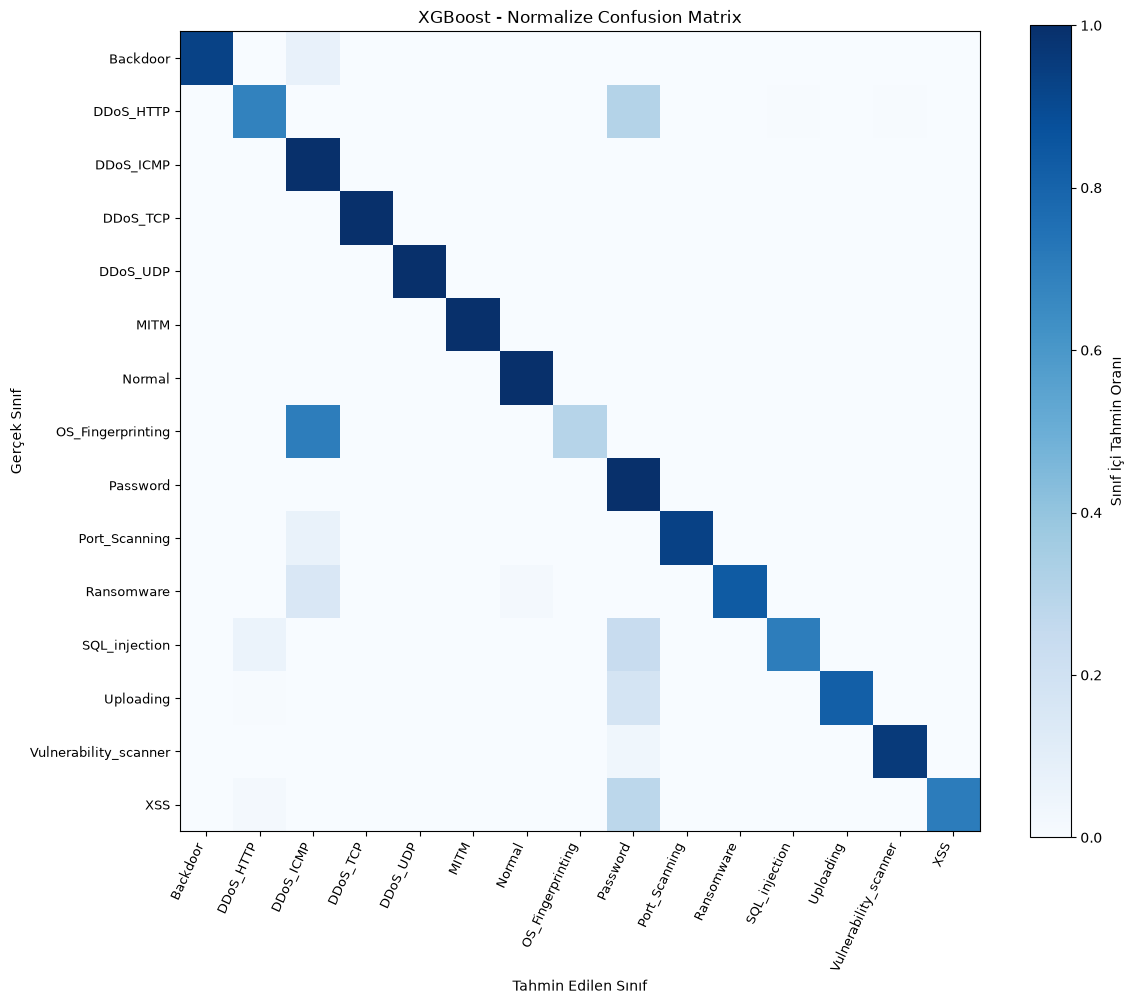


Sınıf bazlı analiz tamamlandı.


In [2]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Proje klasörleri
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
veri = proje / "Calisma_Verileri"
modeller = proje / "Modeller"

# Test verisi
df = pd.read_csv(veri / "EdgeIIoT_Test_Secilmis.csv")

X_test = df.drop(columns=["Attack_label", "Attack_type"])
y_test = df["Attack_type"]

# Eğitilmiş XGBoost modelini yükleme
model = joblib.load(modeller / "08_04_XGBoost.joblib")

kodlayici = joblib.load(
    modeller / "08_04_XGBoost_LabelEncoder.joblib"
)

# Tahmin
tahmin_kodlu = model.predict(X_test)

y_pred = kodlayici.inverse_transform(
    np.asarray(tahmin_kodlu, dtype=int)
)

siniflar = kodlayici.classes_

# Sınıf bazında performans
rapor = classification_report(
    y_test,
    y_pred,
    labels=siniflar,
    output_dict=True,
    zero_division=0
)

sonuclar = pd.DataFrame([
    {
        "Sınıf": sinif,
        "Precision": round(rapor[sinif]["precision"], 4),
        "Recall": round(rapor[sinif]["recall"], 4),
        "F1-score": round(rapor[sinif]["f1-score"], 4),
        "Test Kaydı": int(rapor[sinif]["support"])
    }
    for sinif in siniflar
])

print("XGBOOST - SINIF BAZLI PERFORMANS")
display(sonuclar.sort_values("Recall"))

# Normalize Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=siniflar,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(siniflar)))
ax.set_yticks(range(len(siniflar)))

ax.set_xticklabels(siniflar, rotation=65, ha="right", fontsize=9)
ax.set_yticklabels(siniflar, fontsize=9)

ax.set_xlabel("Tahmin Edilen Sınıf")
ax.set_ylabel("Gerçek Sınıf")
ax.set_title("XGBoost - Normalize Confusion Matrix")

fig.colorbar(im, ax=ax, label="Sınıf İçi Tahmin Oranı")

plt.tight_layout()

# Grafiği kaydetme
grafikler = proje / "Grafikler"
grafikler.mkdir(parents=True, exist_ok=True)

plt.savefig(
    grafikler / "09_02_XGBoost_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Sonuç tablosunu kaydetme
sonuclar.to_csv(
    veri / "09_02_XGBoost_Sinif_Performansi.csv",
    index=False
)

assert len(df) == 79999
assert len(sonuclar) == 15

print("\nSınıf bazlı analiz tamamlandı.")



### 9.2. Confusion Matrix ve Sınıf Bazlı Performans — Sonuç ve Yorum

XGBoost modeli, 79.999 test kaydı üzerinde 15 trafik sınıfı açısından değerlendirilmiştir.

**Elde Edilen Bulgular:**

- DDoS_TCP, DDoS_UDP ve DDoS_ICMP sınıflarında Recall %100 olarak hesaplanmıştır.
- MITM sınıfındaki 60 test kaydının tamamı doğru sınıflandırılmıştır.
- OS_Fingerprinting sınıfında Recall %30 düzeyinde kalmıştır.
- DDoS_HTTP ve XSS sınıflarında diğer bazı sınıflara göre daha düşük Recall değerleri gözlemlenmiştir.

**Değerlendirme:**

Normalize edilmiş Confusion Matrix, modelin özellikle bazı DDoS sınıflarında yüksek başarı gösterdiğini ortaya koymuştur.

Bununla birlikte OS_Fingerprinting sınıfındaki 60 kayıttan yalnızca 18'i doğru tahmin edilmiştir. Diğer 42 kayıt farklı trafik sınıflarıyla karıştırılmıştır.

Bu durum, genel Accuracy değeri yüksek olsa bile bazı azınlık saldırı sınıflarında önemli tespit eksiklikleri bulunabileceğini göstermektedir.

MITM sınıfındaki yüksek başarı da örnekleme ve veri toplama özelliklerinden bağımsız değerlendirilmemelidir.

**Sonuç:**

XGBoost modelinin bütün sınıflarda eşit düzeyde başarılı olmadığı belirlenmiştir.

Bu nedenle model performansının yalnızca Accuracy ile değil, sınıf bazlı Recall, Precision, F1-score ve Confusion Matrix ile değerlendirilmesi gerektiği görülmüştür.

Veri setinin örnekleme yaklaşımı ve olası veri sızıntısı riskleri, sonuçların gerçek ağ ortamlarına genellenmesini sınırlandırmaktadır.



## 9.3. İkili Saldırı Tespiti ve Genel Değerlendirme

**Amaç:** Eğitilmiş dört modelin normal ağ trafiği ile saldırı trafiğini ayırt etme başarısını incelemek.

**Yöntem:** Modellerin 15 sınıflı tahminleri Normal (0) ve Attack (1) olmak üzere iki gruba dönüştürülecektir.

79.999 test kaydı üzerinde Accuracy, saldırı Precision, saldırı Recall, saldırı F1-score ve Normal Recall hesaplanacaktır.

**Beklenen Çıktı:** Dört modelin ikili saldırı tespiti sonuçlarını karşılaştıran tablo.

**Önemli Not:** Bu işlem ayrı bir ikili model eğitimi değildir. Mevcut çok sınıflı modellerin tahminleri iki sınıfa indirgenmektedir. Test verileri üzerinde parametre ayarlaması yapılmayacaktır.


In [3]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
veri = proje / "Calisma_Verileri"
modeller = proje / "Modeller"

# Test verisini hazırlama
df = pd.read_csv(veri / "EdgeIIoT_Test_Secilmis.csv")

X_test = df.drop(columns=["Attack_label", "Attack_type"])
y_gercek = (df["Attack_type"] != "Normal").astype(int)

model_dosyalari = {
    "Logistic Regression": "08_01_Logistic_Regression.joblib",
    "Decision Tree": "08_02_Decision_Tree.joblib",
    "Random Forest": "08_03_Random_Forest.joblib",
    "XGBoost": "08_04_XGBoost.joblib"
}

kodlayici = joblib.load(
    modeller / "08_04_XGBoost_LabelEncoder.joblib"
)

sonuclar = []

for ad, dosya in model_dosyalari.items():

    model = joblib.load(modeller / dosya)
    tahmin = model.predict(X_test)

    if ad == "XGBoost":
        tahmin = kodlayici.inverse_transform(
            np.asarray(tahmin, dtype=int)
        )

    # Çok sınıflı tahminleri ikili sınıfa dönüştürme
    y_tahmin = (np.asarray(tahmin) != "Normal").astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_gercek, y_tahmin, labels=[0, 1]
    ).ravel()

    sonuclar.append({
        "Model": ad,
        "Accuracy (%)": round(
            accuracy_score(y_gercek, y_tahmin) * 100, 2
        ),
        "Attack Precision (%)": round(
            precision_score(y_gercek, y_tahmin) * 100, 2
        ),
        "Attack Recall (%)": round(
            recall_score(y_gercek, y_tahmin) * 100, 2
        ),
        "Attack F1 (%)": round(
            f1_score(y_gercek, y_tahmin) * 100, 2
        ),
        "Normal Recall (%)": round(
            tn / (tn + fp) * 100, 2
        ),
        "Kaçırılan Saldırı": int(fn),
        "Yanlış Alarm": int(fp)
    })

sonuc = pd.DataFrame(sonuclar)

print("NORMAL / ATTACK KARŞILAŞTIRMASI")
print("Test kaydı:", len(df))

display(sonuc)

sonuc.to_csv(
    veri / "09_03_Ikili_Saldiri_Tespiti.csv",
    index=False
)

assert len(df) == 79999
print("\nİkili saldırı tespiti analizi tamamlandı.")


NORMAL / ATTACK KARŞILAŞTIRMASI
Test kaydı: 79999


,Model,Accuracy (%),Attack Precision (%),Attack Recall (%),Attack F1 (%),Normal Recall (%),Kaçırılan Saldırı,Yanlış Alarm
0,Logistic Regression,99.97,99.93,100.0,99.96,99.94,0,27
1,Decision Tree,99.99,99.98,100.0,99.99,99.99,0,6
2,Random Forest,100.00,99.99,100.0,100.00,99.99,0,3
3,XGBoost,99.98,99.97,100.0,99.98,99.97,1,11



İkili saldırı tespiti analizi tamamlandı.



### 9.3. İkili Saldırı Tespiti — Sonuç ve Yorum

79.999 test kaydı üzerinde dört modelin çok sınıflı tahminleri Normal ve Attack olmak üzere iki gruba dönüştürülerek değerlendirilmiştir.

#### Elde Edilen Bulgular

| Model | Accuracy (%) | Attack F1 (%) | Kaçırılan Saldırı | Yanlış Alarm |
|---|---:|---:|---:|---:|
| Logistic Regression | 99,97 | 99,96 | 0 | 27 |
| Decision Tree | 99,99 | 99,99 | 0 | 6 |
| Random Forest | 100,00 | 100,00 | 0 | 3 |
| XGBoost | 99,98 | 99,98 | 1 | 11 |

#### Bulguların Değerlendirilmesi

Dört modelin de Normal ve Attack ayrımında yüksek performans gösterdiği gözlemlenmiştir.

Random Forest modeli, test kümesinde saldırı kaydı kaçırmadan yalnızca üç yanlış alarm üretmiştir.

XGBoost modelinde ise bir saldırı kaydı Normal olarak tahmin edilmiştir. Attack Recall değerinin tabloda %100,00 görünmesi yuvarlamadan kaynaklanmaktadır.

Çok sınıflı değerlendirmede XGBoost daha yüksek Macro F1-score elde ederken ikili değerlendirmede Random Forest daha az yanlış alarm üretmiştir.

Bu farklılık, bir saldırı türünün başka bir saldırı türüyle karıştırılmasının ikili saldırı tespitinde hata sayılmamasından kaynaklanmaktadır.

#### Çalışmanın Sınırlılıkları

Bu analizde ayrı ikili sınıflandırma modelleri eğitilmemiş, mevcut çok sınıflı modellerin tahminleri iki gruba dönüştürülmüştür.

Ayrıca veri setinin örnekleme yöntemi, veri toplama özellikleri ve benzer ağ kayıtlarının eğitim ve test kümelerine dağılma olasılığı değerlendirme sonuçlarını etkileyebilir.

Dolayısıyla elde edilen yüksek performans değerleri, modellerin bağımsız ve gerçek ağ ortamlarında aynı başarıyı göstereceğini garanti etmemektedir.

#### Sonuç

Dört modelin ikili saldırı tespiti performansı değerlendirilmiştir.

Mevcut test kümesinde Random Forest daha az yanlış alarm üretirken XGBoost çok sınıflı sınıflandırmada daha yüksek Macro F1-score elde etmiştir.

Model değerlendirme aşamasının planlanan temel analizleri tamamlanmıştır.



### Nihai Trafik Sınıflandırma Sonuçlarının CSV Dosyasına Aktarılması

**Amaç:** Test kayıtlarının gerçek trafik sınıfları ile makine öğrenmesi modellerinin tahminlerini karşılaştırılabilir bir CSV dosyasına kaydetmek.

**Yöntem:** XGBoost modeliyle 15 sınıflı tahminler, Random Forest modeliyle Normal/Attack tahminleri oluşturulacaktır.

**Beklenen Çıktı:** 79.999 test kaydı için gerçek sınıfları, tahmin edilen sınıfları ve doğru/yanlış tahmin bilgilerini içeren sonuç dosyası.

**Not:** Eğitim kayıtları bağımsız test sonuçlarına dahil edilmeyecektir.


In [4]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
veri = proje / "Calisma_Verileri"
modeller = proje / "Modeller"

# Test verilerini okuma
df = pd.read_csv(veri / "EdgeIIoT_Test_Secilmis.csv")

X_test = df.drop(columns=["Attack_label", "Attack_type"])

# Eğitilmiş modelleri yükleme
xgb = joblib.load(modeller / "08_04_XGBoost.joblib")
rf = joblib.load(modeller / "08_03_Random_Forest.joblib")
kodlayici = joblib.load(
    modeller / "08_04_XGBoost_LabelEncoder.joblib"
)

# 15 sınıflı XGBoost tahminleri
xgb_tahmin = kodlayici.inverse_transform(
    np.asarray(xgb.predict(X_test), dtype=int)
)

# İkili Random Forest tahminleri
rf_tahmin = rf.predict(X_test)

gercek_durum = np.where(
    df["Attack_type"] == "Normal", "Normal", "Attack"
)

rf_durum = np.where(
    rf_tahmin == "Normal", "Normal", "Attack"
)

# Nihai sonuç tablosunu oluşturma
sonuc = pd.DataFrame({
    "Kayit_No": np.arange(1, len(df) + 1),
    "Gercek_Trafik_Turu": df["Attack_type"],
    "XGBoost_Tahmin_Turu": xgb_tahmin,
    "Gercek_Durum": gercek_durum,
    "RandomForest_Tahmin_Durum": rf_durum
})

sonuc["XGBoost_Sonuc"] = np.where(
    sonuc["Gercek_Trafik_Turu"]
    == sonuc["XGBoost_Tahmin_Turu"],
    "Dogru", "Yanlis"
)

sonuc["RF_Ikili_Sonuc"] = np.where(
    sonuc["Gercek_Durum"]
    == sonuc["RandomForest_Tahmin_Durum"],
    "Dogru", "Yanlis"
)

# CSV olarak kaydetme
cikis = veri / "09_Nihai_Trafik_Tahminleri.csv"
sonuc.to_csv(cikis, index=False, encoding="utf-8-sig")

print("Toplam test kaydı:", len(sonuc))
print("\nİlk 10 tahmin:")
display(sonuc.head(10))

print("\nRandom Forest Normal/Attack tahmin dağılımı:")
display(sonuc["RandomForest_Tahmin_Durum"].value_counts())

assert len(sonuc) == 79999

print("\nNihai sonuç dosyası:", cikis)


Toplam test kaydı: 79999

İlk 10 tahmin:


,Kayit_No,Gercek_Trafik_Turu,XGBoost_Tahmin_Turu,Gercek_Durum,RandomForest_Tahmin_Durum,XGBoost_Sonuc,RF_Ikili_Sonuc
0,1,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
1,2,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
2,3,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
3,4,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
4,5,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
5,6,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
6,7,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
7,8,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
8,9,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru
9,10,Backdoor,Backdoor,Attack,Attack,Dogru,Dogru



Random Forest Normal/Attack tahmin dağılımı:


RandomForest_Tahmin_Durum
Normal    42754
Attack    37245
Name: count, dtype: int64


Nihai sonuç dosyası: E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\09_Nihai_Trafik_Tahminleri.csv



## 9.4. Tüm Veri Setinin Sınıflandırılması ve Nihai Sonuçların Kaydedilmesi

**Amaç:** Veri ön işleme sonrasında elde edilen 399.992 ağ trafiği kaydının tamamı için sınıflandırma tahminleri oluşturmak ve sonuçları CSV dosyalarına aktarmak.

**Yöntem:**

- Eğitim ve test veri kümeleri kullanılacaktır.
- XGBoost modeli ile 15 trafik sınıfı tahmin edilecektir.
- Random Forest modeli ile Normal/Attack tahmini elde edilecektir.
- Gerçek etiketlerle model tahminleri karşılaştırılacaktır.
- Tüm kayıtlar ve bağımsız test kayıtları ayrı CSV dosyalarına kaydedilecektir.

**Beklenen Çıktı:**

1. 399.992 kayıt içeren genel trafik sınıflandırma dosyası.
2. 79.999 kayıt içeren test sınıflandırma dosyası.
3. Normal/Attack tahmin dağılımını gösteren özet tablo.

**Önemli Not:** Eğitim kayıtları model tarafından daha önce görülmüştür. Bu nedenle tüm veri setinin sonuçları bağımsız test performansı olarak değerlendirilmemelidir.


In [7]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# ==================================================
# 1. PROJE KLASÖRLERİ
# ==================================================

proje = Path(r"E:\Data mining\Network_Intrusion_Detection")

veri = proje / "Calisma_Verileri"
modeller = proje / "Modeller"

# ==================================================
# 2. EĞİTİM VE TEST VERİLERİNİ YÜKLEME
# ==================================================

train = pd.read_csv(
    veri / "EdgeIIoT_Train_Secilmis.csv"
)

test = pd.read_csv(
    veri / "EdgeIIoT_Test_Secilmis.csv"
)

print("Train kayıt sayısı:", len(train))
print("Test kayıt sayısı:", len(test))
print("Toplam kayıt sayısı:", len(train) + len(test))

assert len(train) == 319993
assert len(test) == 79999

# ==================================================
# 3. EĞİTİLMİŞ MODELLERİ YÜKLEME
# ==================================================

xgb = joblib.load(
    modeller / "08_04_XGBoost.joblib"
)

rf = joblib.load(
    modeller / "08_03_Random_Forest.joblib"
)

etiket_kodlayici = joblib.load(
    modeller / "08_04_XGBoost_LabelEncoder.joblib"
)

# ==================================================
# 4. GİRİŞ ÖZNİTELİKLERİNİ BELİRLEME
# ==================================================

hedefler = ["Attack_label", "Attack_type"]

oz_nitelikler = [
    sutun for sutun in train.columns
    if sutun not in hedefler
]

assert len(oz_nitelikler) == 20

assert [
    sutun for sutun in test.columns
    if sutun not in hedefler
] == oz_nitelikler

# ==================================================
# 5. SINIFLANDIRMA FONKSİYONU
# ==================================================

def siniflandir(df, veri_grubu):

    X = df[oz_nitelikler]

    # XGBoost: 15 trafik sınıfı tahmini
    xgb_kodlu_tahmin = xgb.predict(X)

    xgb_tahmin = etiket_kodlayici.inverse_transform(
        np.asarray(xgb_kodlu_tahmin, dtype=int)
    )

    # Random Forest: 15 sınıflı tahmin
    rf_tahmin = rf.predict(X)

    # Gerçek sınıflar
    gercek_tur = df["Attack_type"].to_numpy()

    # Normal / Attack dönüşümü
    gercek_durum = np.where(
        gercek_tur == "Normal",
        "Normal",
        "Attack"
    )

    xgb_durum = np.where(
        xgb_tahmin == "Normal",
        "Normal",
        "Attack"
    )

    rf_durum = np.where(
        rf_tahmin == "Normal",
        "Normal",
        "Attack"
    )

    # Sonuç tablosu
    sonuc = pd.DataFrame({
        "Veri_Grubu": veri_grubu,
        "Gercek_Trafik_Turu": gercek_tur,
        "Gercek_Durum": gercek_durum,
        "XGBoost_Tahmin_Turu": xgb_tahmin,
        "XGBoost_Tahmin_Durum": xgb_durum,
        "RandomForest_Tahmin_Durum": rf_durum
    })

    # 15 sınıflı tahmin doğruluğu
    sonuc["XGBoost_15Sinif_Sonuc"] = np.where(
        gercek_tur == xgb_tahmin,
        "Dogru",
        "Yanlis"
    )

    # İkili sınıflandırma doğruluğu
    sonuc["RF_Ikili_Sonuc"] = np.where(
        gercek_durum == rf_durum,
        "Dogru",
        "Yanlis"
    )

    return sonuc


# ==================================================
# 6. TRAIN VE TEST KAYITLARINI SINIFLANDIRMA
# ==================================================

train_sonuc = siniflandir(train, "Train")

test_sonuc = siniflandir(test, "Test")

# Tüm sonuçları birleştirme
tum_sonuc = pd.concat(
    [train_sonuc, test_sonuc],
    ignore_index=True
)

# Kayıt numarası ekleme
tum_sonuc.insert(
    0,
    "Sonuc_Kayit_No",
    np.arange(1, len(tum_sonuc) + 1)
)

# Sadece test sonuçları
test_sonuc = tum_sonuc[
    tum_sonuc["Veri_Grubu"] == "Test"
].copy()

# ==================================================
# 7. SONUÇLARI CSV DOSYALARINA KAYDETME
# ==================================================

tum_dosya = veri / "09_Tum_Trafik_Tahminleri.csv"

test_dosya = veri / "09_Test_Trafik_Tahminleri.csv"

tum_sonuc.to_csv(
    tum_dosya,
    index=False,
    encoding="utf-8-sig"
)

test_sonuc.to_csv(
    test_dosya,
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 8. KONTROLLER VE SONUÇLAR
# ==================================================

assert len(tum_sonuc) == 399992
assert len(test_sonuc) == 79999

print("\n" + "=" * 55)
print("TÜM VERİ SETİ SINIFLANDIRMA SONUCU")
print("=" * 55)

print("Toplam sınıflandırılan kayıt:", len(tum_sonuc))
print("Train kayıtları:", len(train_sonuc))
print("Test kayıtları:", len(test_sonuc))

print("\nNORMAL / ATTACK TAHMİN DAĞILIMI")
print("-" * 40)

display(
    tum_sonuc["RandomForest_Tahmin_Durum"]
    .value_counts()
    .rename_axis("Trafik Durumu")
    .reset_index(name="Kayıt Sayısı")
)

print("\nİLK 10 SINIFLANDIRMA SONUCU")
print("-" * 40)

display(tum_sonuc.head(10))

print("\nOLUŞTURULAN CSV DOSYALARI")
print("-" * 40)

print("1.", tum_dosya)
print("2.", test_dosya)

print("\nTüm kayıtların sınıflandırılması tamamlandı.")


Train kayıt sayısı: 319993
Test kayıt sayısı: 79999
Toplam kayıt sayısı: 399992

TÜM VERİ SETİ SINIFLANDIRMA SONUCU
Toplam sınıflandırılan kayıt: 399992
Train kayıtları: 319993
Test kayıtları: 79999

NORMAL / ATTACK TAHMİN DAĞILIMI
----------------------------------------


,Trafik Durumu,Kayıt Sayısı
0,Normal,213776
1,Attack,186216



İLK 10 SINIFLANDIRMA SONUCU
----------------------------------------


,Sonuc_Kayit_No,Veri_Grubu,Gercek_Trafik_Turu,Gercek_Durum,XGBoost_Tahmin_Turu,XGBoost_Tahmin_Durum,RandomForest_Tahmin_Durum,XGBoost_15Sinif_Sonuc,RF_Ikili_Sonuc
0,1,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
1,2,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
2,3,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
3,4,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
4,5,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
5,6,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
6,7,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
7,8,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
8,9,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru
9,10,Train,Backdoor,Attack,Backdoor,Attack,Attack,Dogru,Dogru



OLUŞTURULAN CSV DOSYALARI
----------------------------------------
1. E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\09_Tum_Trafik_Tahminleri.csv
2. E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\09_Test_Trafik_Tahminleri.csv

Tüm kayıtların sınıflandırılması tamamlandı.



## 9.5. Gerçek Trafik Dağılımı ve Model Tahminlerinin Karşılaştırılması

### Amaç

Bu çalışmanın amacı, 399.992 ağ trafiği kaydı içerisinde gerçekte kaç Normal ve kaç Attack kaydı bulunduğunu belirlemek ve Random Forest modelinin tahminlerini gerçek etiketlerle karşılaştırmaktır.

Ayrıca modelin doğru ve yanlış sınıflandırma sayılarının eğitim ve test veri kümeleri üzerinde ayrı ayrı incelenmesi amaçlanmaktadır.

### Yöntem

Önceki aşamada oluşturulan `09_Tum_Trafik_Tahminleri.csv` dosyası kullanılacaktır.

Analiz kapsamında:

- Gerçek Normal ve Attack kayıtlarının sayıları hesaplanacaktır.
- Random Forest modelinin Normal ve Attack tahminlerinin dağılımı belirlenecektir.
- Gerçek ve tahmin edilen etiketler çapraz tablo (Confusion Matrix) yöntemiyle karşılaştırılacaktır.
- Eğitim ve test veri kümelerinde doğru ve yanlış tahmin sayıları ayrı ayrı hesaplanacaktır.
- Veri setinin tamamındaki doğru ve yanlış tahminlerin toplamı belirlenecektir.

### Beklenen Çıktı

399.992 trafik kaydının gerçek Normal/Attack dağılımı, Random Forest modelinin tahmin dağılımı ve gerçek etiketlerle karşılaştırılması elde edilecektir.

Böylece modelin hangi trafik kayıtlarını doğru sınıflandırdığı ve hangi durumlarda hata yaptığı sayısal olarak değerlendirilebilecektir.

**Önemli Not:** Eğitim verileri modelin öğrenme sürecinde kullanıldığı için tüm veri setine ait doğruluk sonuçları bağımsız test başarısı olarak yorumlanmayacaktır. Modelin genelleme performansı, eğitimde kullanılmayan 79.999 test kaydı üzerinden değerlendirilecektir.


In [8]:

import pandas as pd
from pathlib import Path

proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
dosya = proje / "Calisma_Verileri" / "09_Tum_Trafik_Tahminleri.csv"

df = pd.read_csv(dosya)

# 1. Gerçek trafik dağılımı
print("1. GERÇEK TRAFİK DAĞILIMI")
print("-" * 45)
print(df["Gercek_Durum"].value_counts())

# 2. Random Forest tahmin dağılımı
print("\n2. RANDOM FOREST TAHMİN DAĞILIMI")
print("-" * 45)
print(df["RandomForest_Tahmin_Durum"].value_counts())

# 3. Gerçek ve tahmin karşılaştırması
print("\n3. RANDOM FOREST - GERÇEK / TAHMİN")
print("-" * 45)

karsilastirma = pd.crosstab(
    df["Gercek_Durum"],
    df["RandomForest_Tahmin_Durum"],
    rownames=["Gerçek"],
    colnames=["Tahmin"]
)

display(karsilastirma)

# 4. Train ve Test sonuçlarını ayrı hesaplama
print("\n4. TRAIN / TEST DOĞRULUK KONTROLÜ")
print("-" * 45)

for grup, veri in df.groupby("Veri_Grubu"):

    dogru = (
        veri["Gercek_Durum"]
        == veri["RandomForest_Tahmin_Durum"]
    ).sum()

    yanlis = len(veri) - dogru

    print(f"\n{grup}:")
    print("Toplam kayıt:", len(veri))
    print("Doğru tahmin:", dogru)
    print("Yanlış tahmin:", yanlis)
    print("Doğruluk (%):", round(dogru / len(veri) * 100, 4))

# 5. Tüm veri setinin sonucu
print("\n5. TÜM VERİ SETİ ÖZETİ")
print("-" * 45)

dogru_toplam = (
    df["Gercek_Durum"]
    == df["RandomForest_Tahmin_Durum"]
).sum()

print("Toplam kayıt:", len(df))
print("Doğru tahmin:", dogru_toplam)
print("Yanlış tahmin:", len(df) - dogru_toplam)


1. GERÇEK TRAFİK DAĞILIMI
---------------------------------------------
Gercek_Durum
Normal    213783
Attack    186209
Name: count, dtype: int64

2. RANDOM FOREST TAHMİN DAĞILIMI
---------------------------------------------
RandomForest_Tahmin_Durum
Normal    213776
Attack    186216
Name: count, dtype: int64

3. RANDOM FOREST - GERÇEK / TAHMİN
---------------------------------------------


Tahmin,Attack,Normal
Gerçek,,
Attack,186208,1
Normal,8,213775



4. TRAIN / TEST DOĞRULUK KONTROLÜ
---------------------------------------------

Test:
Toplam kayıt: 79999
Doğru tahmin: 79996
Yanlış tahmin: 3
Doğruluk (%): 99.9962

Train:
Toplam kayıt: 319993
Doğru tahmin: 319987
Yanlış tahmin: 6
Doğruluk (%): 99.9981

5. TÜM VERİ SETİ ÖZETİ
---------------------------------------------
Toplam kayıt: 399992
Doğru tahmin: 399983
Yanlış tahmin: 9



### 9.5. Gerçek Trafik Dağılımı ve Model Tahminleri — Sonuç ve Yorum

399.992 ağ trafiği kaydı üzerinde gerçek trafik etiketleri ile Random Forest modelinin Normal/Attack tahminleri karşılaştırılmıştır.

#### Elde Edilen Bulgular

Gerçek veri dağılımında:

- Normal trafik: 213.783 kayıt
- Attack trafiği: 186.209 kayıt
- Toplam: 399.992 kayıt

Random Forest modelinin tahmin dağılımında:

- Normal: 213.776 kayıt
- Attack: 186.216 kayıt

#### Gerçek ve Tahmin Edilen Trafiklerin Karşılaştırılması

Modelin toplam 399.983 kaydı doğru, 9 kaydı yanlış sınıflandırdığı belirlenmiştir.

Hatalı sınıflandırmalar incelendiğinde:

- 1 saldırı kaydının Normal olarak tahmin edildiği,
- 8 normal trafik kaydının Attack olarak tahmin edildiği görülmüştür.

Modelin tüm veri setindeki doğruluk oranı yaklaşık %99,9978 olarak hesaplanmıştır.

#### Eğitim ve Test Sonuçları

Eğitim veri kümesinde:

- Toplam kayıt: 319.993
- Doğru tahmin: 319.987
- Yanlış tahmin: 6

Test veri kümesinde:

- Toplam kayıt: 79.999
- Doğru tahmin: 79.996
- Yanlış tahmin: 3
- Doğruluk oranı: %99,9962

Test kümesinde saldırı kaydı kaçırılmamış, üç normal trafik kaydı yanlışlıkla saldırı olarak sınıflandırılmıştır.

#### Değerlendirme

Random Forest modelinin Normal ve Attack trafiklerini ayırt etmede mevcut veri seti üzerinde oldukça yüksek başarı gösterdiği görülmüştür.

Ancak tüm veri setine ait sonuçlar, modelin eğitim sırasında gördüğü kayıtları da içermektedir. Bu nedenle genel doğruluk oranı bağımsız test başarısı olarak değerlendirilmemelidir.

Ayrıca benzer ağ kayıtlarının eğitim ve test kümelerine dağılmış olma ihtimali, modelin genelleme başarısı açısından önemli bir sınırlılıktır.

#### Sonuç

Random Forest modelinin 399.992 trafik kaydından 399.983'ünü doğru sınıflandırdığı belirlenmiştir.

Böylece veri setinin tamamına ait Normal/Attack tahminleri oluşturulmuş, gerçek trafik dağılımı ile model tahminleri karşılaştırılmıştır.

Bu bulgular, mevcut veri seti üzerindeki sınıflandırma başarısını göstermekte olup bağımsız ve gerçek ağ ortamlarında aynı performansın elde edileceğini garanti etmemektedir.



## 9.6. Veri Sızıntısı Olasılığı ve Model Güvenilirliği Analizi

### Amaç

Bu aşamanın amacı, eğitim ve test veri kümeleri arasında aynı öznitelik değerlerine sahip kayıtların bulunup bulunmadığını araştırmak ve yüksek sınıflandırma performansının güvenilirliğini değerlendirmektir.

### Yöntem

319.993 eğitim ve 79.999 test kaydında, modellerin kullandığı seçilmiş 20 öznitelik karşılaştırılacaktır.

Her kaydın öznitelik değerlerinden bir imza oluşturularak test kayıtlarında eğitim kümesiyle eşleşen örnekler belirlenecektir.

Test kayıtları iki grupta incelenecektir:

- Eğitim kümesinde aynı öznitelik değerleri bulunan kayıtlar.
- Eğitim kümesinde aynı öznitelik değerleri bulunmayan kayıtlar.

Bu gruplarda Random Forest ve XGBoost modellerinin önceden kaydedilmiş tahmin sonuçları karşılaştırılacaktır.

### Beklenen Çıktı

- Eğitim verilerindeki özniteliklerle eşleşen test kaydı sayısı.
- Eşleşme oranı.
- Eşleşen ve eşleşmeyen test kayıtlarında modellerin doğruluk oranları.
- Sonuçların olası veri sızıntısı ve genellenebilirlik açısından değerlendirilmesi.

**Önemli Not:** Aynı 20 öznitelik değerinin bulunması, ham ağ kayıtlarının tamamen aynı olduğunu veya doğrudan hedef değişken sızıntısı yaşandığını tek başına kanıtlamaz. Bu analiz, olası benzerlik ve genellenebilirlik risklerini inceleyen bir ön kontroldür.


In [9]:

import pandas as pd
from pathlib import Path

# Proje klasörü
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
veri = proje / "Calisma_Verileri"

# Eğitim ve test verilerini yükleme
train = pd.read_csv(veri / "EdgeIIoT_Train_Secilmis.csv")
test = pd.read_csv(veri / "EdgeIIoT_Test_Secilmis.csv")

# Önceden oluşturulan test tahminlerini yükleme
sonuc = pd.read_csv(veri / "09_Test_Trafik_Tahminleri.csv")

# Modellerin kullandığı 20 öznitelik
hedefler = ["Attack_label", "Attack_type"]

oz_nitelikler = [
    c for c in train.columns if c not in hedefler
]

# Veri ve sıralama kontrolleri
assert len(train) == 319993
assert len(test) == 79999
assert len(sonuc) == len(test)
assert len(oz_nitelikler) == 20

assert (
    sonuc["Gercek_Trafik_Turu"].reset_index(drop=True)
    == test["Attack_type"].reset_index(drop=True)
).all()

# Öznitelik değerlerinden imza oluşturma
train_imza = pd.util.hash_pandas_object(
    train[oz_nitelikler], index=False
)

test_imza = pd.util.hash_pandas_object(
    test[oz_nitelikler], index=False
)

# Eğitim kümesinde aynı özellik imzası bulunan test kayıtları
eslesme = test_imza.isin(train_imza.unique()).to_numpy()

eslesen_sayi = int(eslesme.sum())
eslesmeyen_sayi = len(test) - eslesen_sayi

print("VERİ BENZERLİĞİ KONTROLÜ")
print("-" * 50)

print("Eğitim kayıt sayısı:", len(train))
print("Test kayıt sayısı:", len(test))
print("Karşılaştırılan öznitelik:", len(oz_nitelikler))

print("\nEşleşen test kayıtları:", eslesen_sayi)
print("Eşleşmeyen test kayıtları:", eslesmeyen_sayi)

print(
    "Eşleşme oranı (%):",
    round(eslesen_sayi / len(test) * 100, 4)
)

# Test sonuçlarını iki grupta karşılaştırma
satirlar = []

for grup_adi, maske in [
    ("Eşleşen", eslesme),
    ("Eşleşmeyen", ~eslesme)
]:
    alt = sonuc.loc[maske]

    if len(alt) == 0:
        continue

    rf_dogru = (
        alt["RF_Ikili_Sonuc"] == "Dogru"
    ).mean() * 100

    xgb_dogru = (
        alt["XGBoost_15Sinif_Sonuc"] == "Dogru"
    ).mean() * 100

    satirlar.append({
        "Test Grubu": grup_adi,
        "Kayıt Sayısı": len(alt),
        "RF İkili Doğruluk (%)": round(rf_dogru, 4),
        "XGBoost 15 Sınıf Doğruluk (%)": round(xgb_dogru, 4)
    })

karsilastirma = pd.DataFrame(satirlar)

print("\nMODEL PERFORMANSI - BENZERLİK ANALİZİ")
display(karsilastirma)

# Analiz sonuçlarını kaydetme
karsilastirma.to_csv(
    veri / "09_06_Veri_Benzerligi_Analizi.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nVeri benzerliği analizi tamamlandı.")


VERİ BENZERLİĞİ KONTROLÜ
--------------------------------------------------
Eğitim kayıt sayısı: 319993
Test kayıt sayısı: 79999
Karşılaştırılan öznitelik: 20

Eşleşen test kayıtları: 26169
Eşleşmeyen test kayıtları: 53830
Eşleşme oranı (%): 32.7117

MODEL PERFORMANSI - BENZERLİK ANALİZİ


,Test Grubu,Kayıt Sayısı,RF İkili Doğruluk (%),XGBoost 15 Sınıf Doğruluk (%)
0,Eşleşen,26169,99.9885,99.5262
1,Eşleşmeyen,53830,100.0000,99.3257



Veri benzerliği analizi tamamlandı.



### 9.6. Veri Benzerliği ve Model Güvenilirliği — Sonuç ve Yorum

Eğitim ve test veri kümelerinde kullanılan 20 öznitelik üzerinden kayıt benzerliği analizi gerçekleştirilmiştir.

#### Elde Edilen Bulgular

- Eğitim kaydı: 319.993
- Test kaydı: 79.999
- Karşılaştırılan öznitelik: 20
- Eğitim kümesiyle eşleşen test kaydı: 26.169
- Eşleşmeyen test kaydı: 53.830
- Eşleşme oranı: %32,7117

#### Model Performanslarının Karşılaştırılması

| Model | Eşleşen Kayıtlar (%) | Eşleşmeyen Kayıtlar (%) |
|---|---:|---:|
| Random Forest (İkili) | 99,9885 | 100,0000 |
| XGBoost (15 Sınıf) | 99,5262 | 99,3257 |

#### Bulguların Değerlendirilmesi

Test veri kümesindeki 26.169 kaydın, eğitim veri kümesindeki en az bir kayıtla aynı 20 öznitelik değerine sahip olduğu belirlenmiştir.

Bu bulgu, test kayıtlarının yaklaşık üçte birinin modelin eğitim sırasında karşılaştığı öznitelik kombinasyonlarını içerdiğini göstermektedir.

Random Forest modeli, eşleşmeyen test kayıtlarında da yüksek ikili sınıflandırma başarısı göstermiştir.

XGBoost modelinin 15 sınıflı doğruluk oranı ise eşleşen kayıtlarda %99,5262, eşleşmeyen kayıtlarda %99,3257 olarak hesaplanmıştır.

Ancak bu analiz yalnızca seçilmiş 20 özniteliğe dayanmaktadır. Eşleşme bulunması, ham ağ kayıtlarının tamamen aynı olduğunu veya doğrudan hedef değişken sızıntısı yaşandığını tek başına kanıtlamamaktadır.

Benzer şekilde eşleşmeyen kayıtlardaki yüksek doğruluk oranı da modelin yeni ağ ortamlarında aynı başarıyı göstereceğini garanti etmemektedir.

#### Sonuç

Eğitim ve test veri kümeleri arasında önemli düzeyde öznitelik benzerliği bulunduğu tespit edilmiştir.

Elde edilen sonuçlar, veri bölme yönteminin ve kayıtlar arasındaki bağımlılıkların model performansına olası etkilerinin dikkate alınması gerektiğini göstermektedir.

Daha güçlü bir genellenebilirlik değerlendirmesi için, mümkün olduğunda ağ oturumu veya veri toplama gruplarına dayalı bağımsız doğrulama önerilmektedir.


    
## 9.7. Stratified K-Fold Cross Validation

### Amaç

Bu aşamanın amacı, makine öğrenmesi modelinin farklı eğitim ve doğrulama alt kümeleri üzerindeki performansını incelemek ve tek bir eğitim/test ayrımına bağlı sonuçların güvenilirliğini değerlendirmektir.

### Yöntem

Stratified 5-Fold Cross Validation yöntemi uygulanacaktır.

İlk doğrulama çalışmasında, 319.993 eğitim kaydından sınıf dağılımı korunarak 80.000 kayıtlık bir alt örneklem seçilecektir.

Veriler beş kata ayrılacak, her tekrarda dört kat model eğitimi ve bir kat doğrulama için kullanılacaktır.

Veri hazırlama işlemleri ve Mutual Information yöntemiyle 20 öznitelik seçimi, her katın yalnızca eğitim bölümünde öğrenilecektir.

İlk aşamada Decision Tree algoritması değerlendirilecektir.

### Beklenen Çıktı

- Beş doğrulama katına ait Accuracy değerleri.
- Beş kata ait Macro F1-score değerleri.
- Balanced Accuracy sonuçları.
- Ortalama performans ve standart sapma değerleri.
- Eğitim ve doğrulama başarılarının karşılaştırılması.

**Önemli Not:** Bu çalışma, önceki modellerden bağımsız olarak her katta yeniden eğitilen bir doğrulama modeli kullanmaktadır. Veri hazırlama ve örneklem büyüklüğü farklı olduğu için sonuçlar önceki test skorlarıyla doğrudan eşdeğer değildir.

79.999 kayıtlık bağımsız test kümesi bu işlemde kullanılmayacaktır.


In [10]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.tree import DecisionTreeClassifier

from functools import partial

# 1. Proje klasörü
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
veri = proje / "Calisma_Verileri"

# Yalnızca eğitim verisini kullanma
df = pd.read_csv(veri / "EdgeIIoT_Train.csv", low_memory=False)

assert len(df) == 319993
assert df["Attack_type"].nunique() == 15

# 2. Tabakalı alt örneklem
ornek_idx, _ = train_test_split(
    np.arange(len(df)),
    train_size=80000,
    stratify=df["Attack_type"],
    random_state=42
)

ornek = df.iloc[ornek_idx].copy()

# 3. Hedef ve öznitelikleri ayırma
y = ornek["Attack_type"]
X = ornek.drop(columns=["Attack_label", "Attack_type"])

# Önceki çalışmada kullanılan kategorik öznitelikler
kategorik = [
    "http.request.method",
    "http.request.version",
    "mqtt.protoname"
]

# Sayısal dönüşüm gerektiren karma içerikli sütunlar
karma_sayisal = [
    "tcp.srcport",
    "tcp.dstport",
    "tcp.len",
    "udp.port",
    "arp.hw.size",
    "dns.qry.name.len",
    "tcp.connection.fin"
]

# Sayısal sütunları belirleme
sayisal = list(dict.fromkeys(
    X.select_dtypes(include="number").columns.tolist()
    + karma_sayisal
))

sayisal = [c for c in sayisal if c not in kategorik]

# Sayısal dönüşüm
for sutun in sayisal:
    X[sutun] = pd.to_numeric(X[sutun], errors="coerce")

X[sayisal] = X[sayisal].replace(
    [np.inf, -np.inf], np.nan
)

# Kategorik veri tiplerini hazırlama
for sutun in kategorik:
    X[sutun] = X[sutun].fillna("Eksik").astype(str)

# 4. Deterministik yeni öznitelikler
kaynak_port = X["tcp.srcport"]
hedef_port = X["tcp.dstport"]
tcp_uzunluk = X["tcp.len"]

X["tcp_uzunluk_log"] = np.log1p(
    tcp_uzunluk.clip(lower=0)
)

X["tcp_port_cifti_var"] = (
    kaynak_port.gt(0) & hedef_port.gt(0)
).astype(int)

X["tcp_hedef_bilinen_port"] = (
    hedef_port.between(1, 1023)
).astype(int)

X["http_istegi_var"] = (
    X["http.request.method"].str.upper().isin(
        ["GET", "POST", "PUT", "DELETE",
         "HEAD", "OPTIONS", "PATCH"]
    )
).astype(int)

yeni_sutunlar = [
    "tcp_uzunluk_log",
    "tcp_port_cifti_var",
    "tcp_hedef_bilinen_port",
    "http_istegi_var"
]

sayisal += yeni_sutunlar

# Önceden dışarıda bırakılan diğer metin sütunları
X = X[sayisal + kategorik].copy()

# 5. Her katta yeniden öğrenilecek ön işleme
sayisal_islem = Pipeline([
    ("eksik_doldur", SimpleImputer(
        strategy="median", add_indicator=True
    )),
    ("olcekle", StandardScaler())
])

kategorik_islem = Pipeline([
    ("eksik_doldur", SimpleImputer(
        strategy="most_frequent"
    )),
    ("kodla", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

on_isleme = ColumnTransformer([
    ("sayisal", sayisal_islem, sayisal),
    ("kategorik", kategorik_islem, kategorik)
])

# 6. Özellik seçimi ve model aynı Pipeline içinde
model = Pipeline([
    ("on_isleme", on_isleme),
    ("ozellik_secimi", SelectKBest(
        score_func=partial(
            mutual_info_classif, random_state=42
        ),
        k=20
    )),
    ("siniflandirici", DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=10,
        random_state=42
    ))
])

# 7. Beş katlı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5 KATLI ÇAPRAZ DOĞRULAMA BAŞLIYOR")
print("Kayıt sayısı:", len(X))
print("Sınıf sayısı:", y.nunique())
print("Kat sayısı:", cv.get_n_splits())

skorlar = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Macro_F1": "f1_macro",
        "Balanced_Accuracy": "balanced_accuracy"
    },
    return_train_score=True,
    n_jobs=1
)

# 8. Sonuçlar
sonuc = pd.DataFrame({
    "Kat": range(1, 6),
    "Train_Accuracy": skorlar["train_Accuracy"],
    "Validation_Accuracy": skorlar["test_Accuracy"],
    "Train_Macro_F1": skorlar["train_Macro_F1"],
    "Validation_Macro_F1": skorlar["test_Macro_F1"],
    "Validation_Balanced_Accuracy":
        skorlar["test_Balanced_Accuracy"]
})

print("\n5-FOLD CROSS VALIDATION SONUÇLARI")
display(sonuc.round(4))

print("\nORTALAMA DOĞRULAMA SONUÇLARI")
print(
    "Accuracy:",
    round(sonuc["Validation_Accuracy"].mean(), 4)
)
print(
    "Macro F1:",
    round(sonuc["Validation_Macro_F1"].mean(), 4)
)
print(
    "Macro F1 Standart Sapma:",
    round(sonuc["Validation_Macro_F1"].std(), 4)
)

# Sonuçları kaydetme
sonuc.to_csv(
    veri / "09_07_KFold_Decision_Tree.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nÇapraz doğrulama tamamlandı.")


5 KATLI ÇAPRAZ DOĞRULAMA BAŞLIYOR
Kayıt sayısı: 80000
Sınıf sayısı: 15
Kat sayısı: 5

5-FOLD CROSS VALIDATION SONUÇLARI


,Kat,Train_Accuracy,Validation_Accuracy,Train_Macro_F1,Validation_Macro_F1,Validation_Balanced_Accuracy
0,1,0.9909,0.9893,0.8352,0.8122,0.7665
1,2,0.9909,0.9896,0.8285,0.8172,0.7833
2,3,0.9905,0.9881,0.8194,0.7985,0.7505
3,4,0.9910,0.9885,0.8368,0.7911,0.7465
4,5,0.9912,0.9879,0.8290,0.7824,0.7385



ORTALAMA DOĞRULAMA SONUÇLARI
Accuracy: 0.9887
Macro F1: 0.8003
Macro F1 Standart Sapma: 0.0145

Çapraz doğrulama tamamlandı.



### 9.7.1. Decision Tree — Sonuç ve Yorum

Decision Tree algoritması, 80.000 eğitim kaydı üzerinde Stratified 5-Fold Cross Validation yöntemiyle değerlendirilmiştir.

#### Elde Edilen Bulgular

- Doğrulama katı sayısı: 5
- Kullanılan kayıt sayısı: 80.000
- Trafik sınıfı sayısı: 15
- Ortalama Validation Accuracy: %98,87
- Ortalama Validation Macro F1-score: %80,03
- Macro F1 standart sapması: 0,0145
- Ortalama Balanced Accuracy: yaklaşık %75,71

#### Değerlendirme

Beş farklı doğrulama katında Accuracy değerleri %98,79 ile %98,96 arasında değişmiştir.

Macro F1-score değerleri ise %78,24 ile %81,72 arasında gerçekleşmiştir.

Eğitim ve doğrulama sonuçları arasında belirli performans farklılıkları bulunmakla birlikte Accuracy açısından büyük bir düşüş gözlemlenmemiştir.

Ancak Macro F1-score değerinin Accuracy değerinden düşük olması, bazı trafik sınıflarının diğerlerine göre daha zor sınıflandırıldığını göstermektedir.

Bu analizde veri ön işleme ve öznitelik seçimi her doğrulama katının eğitim bölümü üzerinde gerçekleştirilmiştir.

Çalışma 80.000 kayıtlık bir alt örneklem üzerinde yapıldığı için sonuçlar, daha önce 319.993 eğitim kaydıyla eğitilen modelin test performansıyla doğrudan eşdeğer değildir.

#### Sonuç

Decision Tree modeli, beş katlı çapraz doğrulama sonucunda yüksek genel doğruluk ve daha sınırlı sınıf dengesi performansı göstermiştir.

Bununla birlikte benzer ağ kayıtlarının farklı doğrulama katlarına dağılma olasılığı devam etmektedir. Bu nedenle sonuçlar bağımsız bir ağ ortamında doğrulanmış performans olarak değerlendirilmemelidir.



## 9.7.2. Random Forest ile Stratified 5-Fold Cross Validation

### Amaç

Random Forest algoritmasının farklı eğitim ve doğrulama kümeleri üzerindeki performansını değerlendirmek ve Decision Tree sonuçlarıyla karşılaştırılabilecek ölçütler elde etmek.

### Yöntem

Önceki aşamada oluşturulan 80.000 kayıtlık tabakalı eğitim alt örneklemi kullanılacaktır.

Stratified 5-Fold Cross Validation yöntemi uygulanarak model beş farklı eğitim bölümü üzerinde yeniden eğitilecektir.

Her katın eğitim bölümünde veri ön işleme ve Mutual Information ile 20 öznitelik seçimi gerçekleştirilecektir.

Random Forest modeli 100 karar ağacı ile oluşturulacaktır.

### Beklenen Çıktı

- Beş kata ait Train Accuracy ve Validation Accuracy.
- Train ve Validation Macro F1-score değerleri.
- Validation Balanced Accuracy.
- Ortalama doğrulama sonuçları ve standart sapma.
- Karşılaştırma için CSV sonuç dosyası.

**Not:** Bağımsız test verileri kullanılmayacak, doğrulama yalnızca eğitim alt örneklemi üzerinde gerçekleştirilecektir.


In [11]:

import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

# Önceki ön işleme ve öznitelik seçimi
# adımlarını koruyarak modeli kopyalama
model_rf = clone(model)

# Decision Tree yerine Random Forest kullanma
model_rf.set_params(
    siniflandirici=RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=4
    )
)

print("RANDOM FOREST - 5 KATLI ÇAPRAZ DOĞRULAMA")
print("-" * 50)
print("Kayıt sayısı:", len(X))
print("Sınıf sayısı:", y.nunique())
print("Kat sayısı:", cv.get_n_splits())

# Çapraz doğrulama
rf_skorlar = cross_validate(
    model_rf,
    X,
    y,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Macro_F1": "f1_macro",
        "Balanced_Accuracy": "balanced_accuracy"
    },
    return_train_score=True,
    n_jobs=1
)

# Sonuç tablosu
rf_sonuc = pd.DataFrame({
    "Kat": range(1, 6),
    "Train_Accuracy": rf_skorlar["train_Accuracy"],
    "Validation_Accuracy": rf_skorlar["test_Accuracy"],
    "Train_Macro_F1": rf_skorlar["train_Macro_F1"],
    "Validation_Macro_F1": rf_skorlar["test_Macro_F1"],
    "Validation_Balanced_Accuracy":
        rf_skorlar["test_Balanced_Accuracy"]
})

print("\n5-FOLD RANDOM FOREST SONUÇLARI")
display(rf_sonuc.round(4))

print("\nORTALAMA DOĞRULAMA SONUÇLARI")
print(
    "Accuracy:",
    round(rf_sonuc["Validation_Accuracy"].mean(), 4)
)

print(
    "Macro F1:",
    round(rf_sonuc["Validation_Macro_F1"].mean(), 4)
)

print(
    "Macro F1 Standart Sapma:",
    round(rf_sonuc["Validation_Macro_F1"].std(), 4)
)

print(
    "Balanced Accuracy:",
    round(
        rf_sonuc["Validation_Balanced_Accuracy"].mean(),
        4
    )
)

# CSV dosyasına kaydetme
rf_sonuc.to_csv(
    veri / "09_07_KFold_Random_Forest.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nRandom Forest çapraz doğrulama tamamlandı.")


RANDOM FOREST - 5 KATLI ÇAPRAZ DOĞRULAMA
--------------------------------------------------
Kayıt sayısı: 80000
Sınıf sayısı: 15
Kat sayısı: 5

5-FOLD RANDOM FOREST SONUÇLARI


,Kat,Train_Accuracy,Validation_Accuracy,Train_Macro_F1,Validation_Macro_F1,Validation_Balanced_Accuracy
0,1,0.9921,0.9909,0.8592,0.8359,0.7871
1,2,0.9916,0.9905,0.8427,0.8496,0.7948
2,3,0.9915,0.9904,0.8404,0.8500,0.8013
3,4,0.9920,0.9894,0.8536,0.8150,0.7592
4,5,0.9924,0.9898,0.8586,0.8258,0.7727



ORTALAMA DOĞRULAMA SONUÇLARI
Accuracy: 0.9902
Macro F1: 0.8353
Macro F1 Standart Sapma: 0.0152
Balanced Accuracy: 0.783

Random Forest çapraz doğrulama tamamlandı.



### 9.7.2. Random Forest — Sonuç ve Yorum

Random Forest algoritması, 80.000 eğitim kaydı üzerinde Stratified 5-Fold Cross Validation yöntemi kullanılarak değerlendirilmiştir.

#### Elde Edilen Bulgular

- Kullanılan kayıt sayısı: 80.000
- Doğrulama katı: 5
- Trafik sınıfı: 15
- Ortalama Validation Accuracy: %99,02
- Ortalama Validation Macro F1-score: %83,53
- Ortalama Balanced Accuracy: %78,30
- Macro F1 standart sapması: 0,0152

#### Bulguların Değerlendirilmesi

Random Forest modelinin beş doğrulama katındaki Accuracy değerleri %98,94 ile %99,09 arasında değişmiştir.

Macro F1-score değerleri ise %81,50 ile %85,00 arasında gerçekleşmiştir.

Bu sonuçlar, modelin farklı doğrulama bölümlerinde yüksek genel doğruluk sağladığını göstermektedir.

Karşılaştırma sonucunda Random Forest modelinin Decision Tree algoritmasına göre daha yüksek Accuracy, Macro F1-score ve Balanced Accuracy değerleri elde ettiği görülmüştür.

Özellikle Macro F1-score değerindeki artış, Random Forest algoritmasının farklı trafik sınıflarının sınıflandırılmasında daha dengeli sonuçlar verdiğine işaret etmektedir.

Bununla birlikte Balanced Accuracy değerinin genel Accuracy değerinden düşük olması, bazı saldırı sınıflarındaki tespit başarısının sınırlı kaldığını göstermektedir.

Veri ön işleme ve öznitelik seçimi, her doğrulama katının yalnızca eğitim bölümünde öğrenilmiştir. Böylece bu işlemlerden kaynaklanabilecek doğrulama verisi sızıntısı riski azaltılmıştır.

Ancak benzer ağ kayıtlarının farklı katlara dağılma olasılığı devam etmektedir.

#### Sonuç

Random Forest modeli, beş katlı çapraz doğrulamada Decision Tree modelinden daha yüksek performans elde etmiştir.

Sonuçlar, Random Forest algoritmasının mevcut eğitim verileri üzerinde güçlü bir sınıflandırma yaklaşımı olduğunu göstermektedir.

Bununla birlikte sonuçların farklı ağ ortamlarına genellenebilirliği bağımsız veri kümeleri üzerinde ayrıca doğrulanmalıdır.



## 9.7.3. XGBoost ile Stratified 5-Fold Cross Validation

### Amaç

XGBoost algoritmasının farklı eğitim ve doğrulama kümeleri üzerindeki performansını değerlendirmek ve sonuçlarını Decision Tree ile Random Forest algoritmalarıyla karşılaştırmak.

### Yöntem

Önceki aşamalarda kullanılan 80.000 kayıtlık tabakalı eğitim alt örneklemi üzerinde Stratified 5-Fold Cross Validation uygulanacaktır.

Her doğrulama katında veri ön işleme ve Mutual Information yöntemiyle 20 öznitelik seçimi yeniden gerçekleştirilecektir.

XGBoost modeli 60 boosting turu kullanılarak eğitilecektir.

Attack_type hedef değişkenindeki sınıf adları, XGBoost algoritmasının gereksinimine uygun olarak sayısal etiketlere dönüştürülecektir.

### Beklenen Çıktı

Beş doğrulama katı için Train Accuracy, Validation Accuracy, Train Macro F1, Validation Macro F1 ve Balanced Accuracy değerleri hesaplanacaktır.

Ortalama başarı ve standart sapma değerleri elde edilerek diğer modellerle karşılaştırma yapılacaktır.

**Önemli Not:** Hedef etiketlerin sayısal kodlanması yalnızca sınıf isimlerinin temsilini değiştirmektedir. Bağımsız test veri kümesi çapraz doğrulama aşamasında kullanılmayacaktır.


In [12]:

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier

# ============================================
# 1. HEDEF ETİKETLERİNİ SAYISALLAŞTIRMA
# ============================================

etiket_kodlayici_cv = LabelEncoder()

y_xgb = etiket_kodlayici_cv.fit_transform(y)

assert len(X) == 80000
assert len(np.unique(y_xgb)) == 15

# ============================================
# 2. XGBOOST PIPELINE OLUŞTURMA
# ============================================

# Önceki ön işleme ve özellik seçimini koruma
model_xgb_cv = clone(model)

model_xgb_cv.set_params(
    siniflandirici=XGBClassifier(
        n_estimators=60,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=4
    )
)

# ============================================
# 3. STRATIFIED 5-FOLD CROSS VALIDATION
# ============================================

print("XGBOOST - 5 KATLI ÇAPRAZ DOĞRULAMA")
print("-" * 50)

print("Kayıt sayısı:", len(X))
print("Sınıf sayısı:", len(np.unique(y_xgb)))
print("Kat sayısı:", cv.get_n_splits())

xgb_skorlar = cross_validate(
    model_xgb_cv,
    X,
    y_xgb,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Macro_F1": "f1_macro",
        "Balanced_Accuracy": "balanced_accuracy"
    },
    return_train_score=True,
    n_jobs=1
)

# ============================================
# 4. SONUÇ TABLOSU
# ============================================

xgb_sonuc = pd.DataFrame({
    "Kat": range(1, 6),
    "Train_Accuracy": xgb_skorlar["train_Accuracy"],
    "Validation_Accuracy": xgb_skorlar["test_Accuracy"],
    "Train_Macro_F1": xgb_skorlar["train_Macro_F1"],
    "Validation_Macro_F1": xgb_skorlar["test_Macro_F1"],
    "Validation_Balanced_Accuracy":
        xgb_skorlar["test_Balanced_Accuracy"]
})

print("\n5-FOLD XGBOOST SONUÇLARI")

display(xgb_sonuc.round(4))

# ============================================
# 5. ORTALAMA PERFORMANS
# ============================================

print("\nORTALAMA DOĞRULAMA SONUÇLARI")

print(
    "Accuracy:",
    round(xgb_sonuc["Validation_Accuracy"].mean(), 4)
)

print(
    "Macro F1:",
    round(xgb_sonuc["Validation_Macro_F1"].mean(), 4)
)

print(
    "Macro F1 Standart Sapma:",
    round(xgb_sonuc["Validation_Macro_F1"].std(), 4)
)

print(
    "Balanced Accuracy:",
    round(
        xgb_sonuc["Validation_Balanced_Accuracy"].mean(),
        4
    )
)

# ============================================
# 6. SONUÇLARI CSV OLARAK KAYDETME
# ============================================

xgb_sonuc.to_csv(
    veri / "09_07_KFold_XGBoost.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nXGBoost çapraz doğrulama tamamlandı.")


XGBOOST - 5 KATLI ÇAPRAZ DOĞRULAMA
--------------------------------------------------
Kayıt sayısı: 80000
Sınıf sayısı: 15
Kat sayısı: 5

5-FOLD XGBOOST SONUÇLARI


,Kat,Train_Accuracy,Validation_Accuracy,Train_Macro_F1,Validation_Macro_F1,Validation_Balanced_Accuracy
0,1,0.9936,0.9936,0.8998,0.8978,0.8522
1,2,0.9937,0.9932,0.8982,0.8823,0.8395
2,3,0.9935,0.9931,0.8933,0.8888,0.8457
3,4,0.9942,0.9924,0.9087,0.8757,0.8230
4,5,0.9939,0.9917,0.9002,0.8566,0.7984



ORTALAMA DOĞRULAMA SONUÇLARI
Accuracy: 0.9928
Macro F1: 0.8803
Macro F1 Standart Sapma: 0.0155
Balanced Accuracy: 0.8317

XGBoost çapraz doğrulama tamamlandı.



### 9.7.3. XGBoost — Sonuç ve Yorum

XGBoost algoritması, 80.000 eğitim kaydı üzerinde Stratified 5-Fold Cross Validation yöntemi kullanılarak değerlendirilmiştir.

#### Elde Edilen Bulgular

- Kullanılan kayıt sayısı: 80.000
- Trafik sınıfı sayısı: 15
- Çapraz doğrulama katı: 5
- Ortalama Validation Accuracy: %99,28
- Ortalama Validation Macro F1-score: %88,03
- Ortalama Balanced Accuracy: %83,17
- Macro F1 standart sapması: 0,0155

#### Bulguların Değerlendirilmesi

XGBoost modelinin beş doğrulama katındaki Accuracy değerleri %99,17 ile %99,36 arasında değişmiştir.

Macro F1-score değerleri ise %85,66 ile %89,78 arasında gerçekleşmiştir.

Eğitim ve doğrulama Accuracy değerleri arasında büyük farklılıklar gözlemlenmemiştir. Bununla birlikte Macro F1-score değerlerinin katlar arasında değişmesi, bazı trafik sınıflarında sınıflandırma başarısının daha değişken olduğunu göstermektedir.

Ön işleme ve Mutual Information ile öznitelik seçimi, çapraz doğrulama Pipeline yapısı içerisinde her kat için yeniden uygulanmıştır.

#### Diğer Modellerle Karşılaştırma

| Model | Ortalama Accuracy (%) | Ortalama Macro F1 (%) | Balanced Accuracy (%) |
|---|---:|---:|---:|
| Decision Tree | 98,87 | 80,03 | 75,71 |
| Random Forest | 99,02 | 83,53 | 78,30 |
| XGBoost | 99,28 | 88,03 | 83,17 |

Üç model karşılaştırıldığında XGBoost algoritmasının tüm performans ölçütlerinde en yüksek ortalama değerlere ulaştığı belirlenmiştir.

Özellikle Macro F1-score değerinin yüksek olması, XGBoost modelinin mevcut doğrulama örnekleminde farklı saldırı türlerini sınıflandırma açısından diğer iki algoritmadan daha dengeli sonuçlar verdiğini göstermektedir.

#### Sınırlılıklar

Bu çalışma, 319.993 eğitim kaydından seçilen 80.000 kayıtlık bir alt örneklem üzerinde gerçekleştirilmiştir.

Tabakalı çapraz doğrulama, sınıf dağılımlarını korumakla birlikte benzer ağ kayıtlarının veya aynı oturuma ait verilerin farklı doğrulama katlarına dağılmasını tamamen engellememektedir.

Bu nedenle sonuçlar, bağımsız ağ ortamlarında doğrulanmış performans olarak değerlendirilmemelidir.

#### Genel Sonuç

Stratified 5-Fold Cross Validation yöntemi kullanılarak Decision Tree, Random Forest ve XGBoost algoritmaları karşılaştırılmıştır.

XGBoost algoritması, %99,28 ortalama Accuracy ve %88,03 ortalama Macro F1-score ile en yüksek genel performansı göstermiştir.

Bu sonuçlar, XGBoost modelinin IoT/IIoT ağ trafiğinde çok sınıflı saldırı tespiti için mevcut deney kapsamında güçlü bir aday olduğunu ortaya koymaktadır.
